# 04 - Mapas: bairros geocodificados

**Objetivo:** substituir as posições simuladas dos bairros por coordenadas reais e olhar o desempenho no mapa.

**Fonte das coordenadas:** OpenStreetMap, via serviço Nominatim (`src/logistica_rotas/ingestao/geocodificacao.py`).
- Dados © colaboradores do OpenStreetMap, licença ODbL.
- Política de uso respeitada: 1 consulta por segundo, aplicação identificada e **cache** em `data/external/bairros_geocodificados.csv` (este notebook só lê o cache; não consulta o serviço).

**Validação de cada bairro:** o resultado precisa ser uma área de bairro (não rua, estação, posto), citar o município e estar a até 9 km do centro dele. Bairros reprovados ficam com posição simulada e são sinalizados.

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.ingestao.geocodificacao import carregar_cache
from logistica_rotas.ingestao.simulacao import BAIRROS
from logistica_rotas.visualizacao import graficos as g
from logistica_rotas.visualizacao.mapas import indicadores_por_bairro, mapa_bairros, salvar_mapa

## 2. Qualidade da geocodificação

In [2]:
cache = carregar_cache()
print(f"{int(cache['valido'].sum())} de {len(cache)} bairros com coordenada real válida")
cache.groupby(["valido", "tipo_osm"], dropna=False).size().rename("bairros").to_frame()

43 de 45 bairros com coordenada real válida


bairros
valido tipo_osm         
False  primary         1
       railway         1
True   quarter         3
       suburb         40

In [3]:
cache.loc[~cache["valido"], ["cidade", "bairro", "tipo_osm", "dist_centro_km", "nome_osm"]]

,cidade,bairro,tipo_osm,dist_centro_km,nome_osm
5,Santo André,Utinga,railway,4.2,"Utinga, Viaduto Juvenal Fontanella, Vila Metal..."
39,Mauá,Barão de Mauá,primary,4.0,"Avenida Barão de Mauá, Jardim Elvira, Jardim C..."


**Leitura:**
- **Utinga (Santo André):** o Nominatim devolveu a *estação* de trem Utinga, não a área do bairro. A estação fica no bairro, mas pela regra (só áreas) ela foi recusada.
- **Barão de Mauá (Mauá):** o resultado foi a *Avenida* Barão de Mauá. Não há bairro com esse nome no OSM - **verificar** se o nome está correto ou se o bairro tem outro nome oficial.
- **Oswaldo Cruz (São Caetano):** a grafia correta no OSM é com "w"; o nome foi corrigido na simulação.

In [4]:
cache.loc[cache["valido"], "dist_centro_km"].describe().to_frame("distância até o centro da cidade (km)")

,distância até o centro da cidade (km)
count,43.0
mean,2.2
std,1.4
min,0.1
25%,1.1
50%,1.8
75%,3.1
max,5.2


## 3. Checagens de coordenadas na base

Diretriz do projeto: WGS84, latitude antes de longitude, dentro do Brasil (lat -34 a 6, lon -74 a -34).

In [5]:
coords = ["lat_origem", "lon_origem", "lat_destino", "lon_destino"]
pd.Series({
    "coordenadas nulas": int(df[coords].isna().sum().sum()),
    "latitude fora do Brasil": int((~df[["lat_origem", "lat_destino"]].stack().between(-34, 6)).sum()),
    "longitude fora do Brasil": int((~df[["lon_origem", "lon_destino"]].stack().between(-74, -34)).sum()),
    "pedidos com bairro de destino de posição simulada": int(df["bairro_destino"].astype(str).isin(
        BAIRROS.loc[BAIRROS["fonte_coordenada"] != "osm", "bairro"]).sum()),
}, name="quantidade").to_frame()

,quantidade
coordenadas nulas,0
latitude fora do Brasil,0
longitude fora do Brasil,0
pedidos com bairro de destino de posição simulada,245


## 4. Indicadores por bairro de destino

In [6]:
bairros = indicadores_por_bairro(df)
colunas = ["cidade", "bairro", "entregas", "atraso_pct", "tempo_mediano_min", "distancia_media_km", "fonte_coordenada"]
pd.concat({"maior atraso": bairros.nlargest(6, "atraso_pct")[colunas],
           "menor atraso": bairros.nsmallest(6, "atraso_pct")[colunas]})

cidade         bairro  entregas  atraso_pct  tempo_mediano_min  distancia_media_km fonte_coordenada
maior atraso 15                   Mauá    Vila Noêmia        92        14.1               13.4                 4.9              osm
             25            Santo André    Vila Luzita       112        13.4               24.4                 7.6              osm
             35  São Bernardo do Campo    Rudge Ramos       152        13.2               21.4                 6.9              osm
             5                 Diadema    Piraporinha       101        12.9               16.9                 5.2              osm
             33  São Bernardo do Campo      Paulicéia       134        12.7               21.8                 6.9              osm
             26  São Bernardo do Campo       Assunção       138        11.6               17.2                 5.8              osm
menor atraso 23            Santo André    Vila Bastos       135         1.5               13.6                 3.9              osm
             39     São Caetano do Sul       Fundação        61         1.6               15.3                 5.5              osm
             22            Santo André  Vila Assunção       137         2.2               14.4                 4.1              osm
             42     São Caetano do Sul   Oswaldo Cruz        82         2.4               13.4                 4.2              osm
             43     São Caetano do Sul    Santa Maria        63         3.2               13.6                 4.3              osm
             19            Santo André         Centro       119         3.4               12.1                 3.7              osm

In [7]:
bairros[["atraso_pct", "distancia_media_km", "tempo_mediano_min"]].corr().round(2)

,atraso_pct,distancia_media_km,tempo_mediano_min
atraso_pct,1.0,0.5,0.5
distancia_media_km,0.5,1.0,0.8
tempo_mediano_min,0.5,0.8,1.0


**Leitura:** a correlação entre atraso e distância média reforça o notebook 03 (distância é o principal fator). Com 50 a 150 entregas por bairro, diferenças de 1 a 2 pontos são ruído - não vale ranquear bairros por elas.

## 5. Mapa estático (para o README)

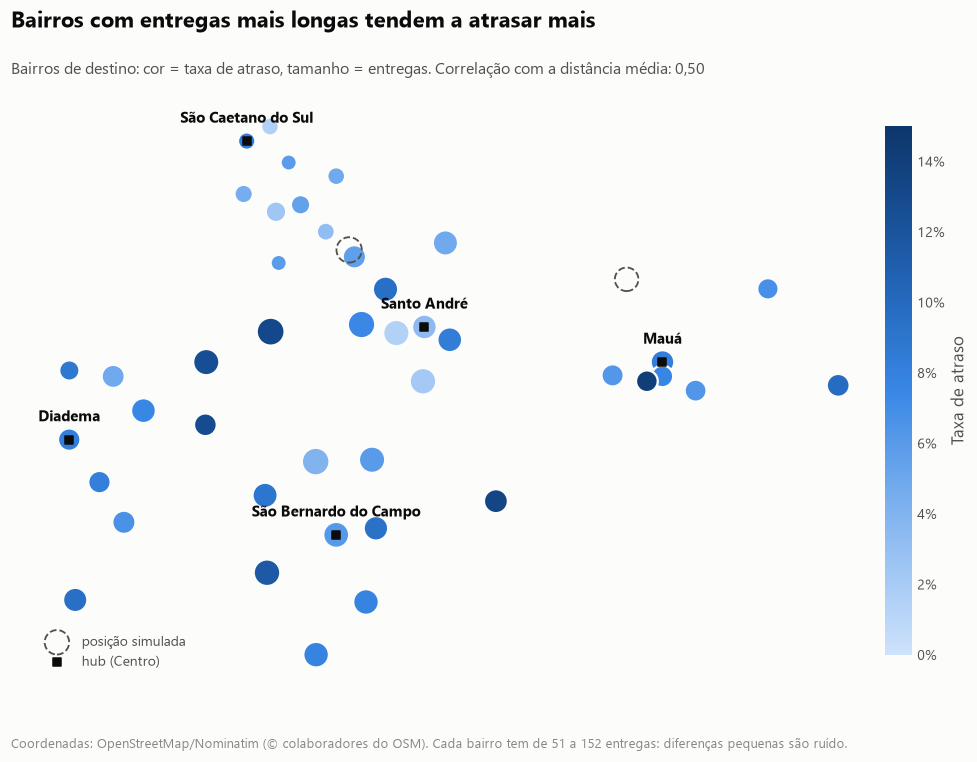

In [8]:
fig = g.mapa_bairros_estatico(bairros)
g.salvar_figura(fig, "07_mapa_bairros_atraso");

## 6. Mapa interativo

Clique nos círculos para ver os números do bairro. Também salvo em `reports/mapa_bairros.html` (abrir no navegador).

In [9]:
mapa = mapa_bairros(df)
salvar_mapa(mapa, "mapa_bairros")
mapa

## 7. Conclusões

- **Geocodificação:** 43 dos 45 bairros têm coordenada real do OpenStreetMap. Utinga caiu numa estação de trem e Barão de Mauá numa avenida, então os dois ficaram com posição simulada e sinalizada. O nome de **Barão de Mauá** precisa ser verificado: não existe bairro com esse nome no OSM.
- **Base:** todas as coordenadas estão dentro do Brasil. 245 pedidos têm destino num bairro com posição simulada (cerca de 5%).
- **Desempenho por bairro:** o atraso tem correlação de 0,5 com a distância média das entregas, o que confirma o notebook 03. Porém, com 50 a 150 entregas por bairro, ranquear bairros por diferenças pequenas seria ler ruído.
- **Mapas gerados:** `reports/figures/07_mapa_bairros_atraso.png` (estático, para o README) e `reports/mapa_bairros.html` (interativo; abrir no navegador).
